# ACC 380K — Notebook 10
## Joins: attaching Compustat financials to store visits

**Notebook version 0.8.2 · October 20, 2026**

**The question:** Did Starbucks earn more revenue per store visit in fiscal 2025 than in fiscal 2019?

To answer it you need two tables side by side: store visits from the foot-traffic data, and revenue from Starbucks's financial statements, as collected by Compustat. Combining two tables is a **join**.

Auditors do this in an **analytical procedure**: build an expectation for revenue from independent, nonfinancial data, such as customer visits, and investigate when the two move apart.

In Colab, choose **File → Save a copy in Drive** and work in your own copy.


## 2:00 Section — live class record

This copy began from **Starter**. Nick edits it during the 2:00 class and saves it at the end. Use Starter when you want a fresh copy of the exercise.


## What you should be able to do

- Read a Compustat table of quarterly financial statement data.
- Work out what two tables need before they can be joined, and join them with `pd.merge`.
- Say which rows an **inner**, **left**, and **outer** join keep, and predict how many rows each returns.
- Explain why a row with no match gets `NaN`, and why `NaN` is not zero.

We build on Notebooks 8 and 9.

Exercise 1 has a **Your turn** box: try it on your own or with your table. Run your work cell, then the collapsed **Check your work** cell below it. A line that starts with `NOT YET` tells you what to fix; revise your work cell and rerun both cells. An optional section at the end has more.

**Read → Predict → Run → Assess → Test**


## Load the data

This notebook uses two files, both downloaded with the class code from Canvas. Paste the code between the quotes in `CLASS_KEY`. Do not share the code or the files.

- `SBUX_main.feather`: weekly foot-traffic estimates for every US Starbucks store, January 2017 to September 2026, the file from Notebook 9 (643.5 MB). `pd.read_feather` reads it into `sbux`.
- `compustat_fundq_sbux.csv`: Starbucks's quarterly financial statement data from Compustat (a few kilobytes). `pd.read_csv` reads it into `fundq`. Compustat is licensed to UT through WRDS, so this file is for the class only.

`!` runs a command outside Python; `curl` saves each file, and `-H` sends the class code. A wrong or missing code gets **403** and the text `Forbidden: check the class code from Canvas.`, which `curl` saves in place of the data, so the read that follows fails. Check the code and run the cell again.

The second cell reads the files and turns the date columns from text into dates, as in Notebook 9. It is separate from the download, so you can rerun it to start over without downloading again.


In [ ]:
CLASS_KEY = ""  # paste the class code from Canvas
!curl -H "X-Class-Key: {CLASS_KEY}" -o SBUX_main.feather https://acc380k-data.nicholashallman.workers.dev/data/SBUX_main.feather
!curl -H "X-Class-Key: {CLASS_KEY}" -o compustat_fundq_sbux.csv https://acc380k-data.nicholashallman.workers.dev/data/compustat_fundq_sbux.csv


In [ ]:
import pandas as pd
sbux = pd.read_feather("SBUX_main.feather")
fundq = pd.read_csv("compustat_fundq_sbux.csv")
sbux["DATE_RANGE_START_dt"] = pd.to_datetime(sbux["DATE_RANGE_START"])
fundq["datadate"] = pd.to_datetime(fundq["datadate"])


## The Compustat data

Compustat, sold by S&P Global, collects companies' financial statements in one consistent layout. `fundq` holds Starbucks's quarterly fundamentals: **one row per fiscal quarter**, dollar amounts in \$ millions.

| Column | Meaning | Units |
|---|---|---|
| `gvkey` | Compustat's permanent company ID | text |
| `tic` | ticker symbol | text |
| `conm` | company name | text |
| `datadate` | last day of the fiscal quarter | date |
| `fyearq` | fiscal year | year |
| `fqtr` | fiscal quarter, 1 to 4 | number |
| `fyr` | month the fiscal year ends (9 = September) | month |
| `rdq` | date the quarter's results were announced | date |
| `revtq` | total revenue | \$ millions |
| `cogsq` | cost of goods sold | \$ millions |
| `xsgaq` | selling, general, and administrative expense | \$ millions |
| `oiadpq` | operating income after depreciation | \$ millions |
| `niq` | net income | \$ millions |
| `atq` | total assets | \$ millions |
| `invtq` | inventory | \$ millions |
| `cshoq` | common shares outstanding | millions of shares |
| `prccq` | share price at quarter end | \$ per share |

**Predict:** How many rows will `fundq` have, and what does one row represent?


In [ ]:
print("Rows:", len(fundq))
fundq[["tic", "datadate", "fyearq", "fqtr", "fyr", "rdq", "revtq", "niq"]].head(8)


39 quarters, from fiscal 2017 Q1 to fiscal 2026 Q3. `fyr` is 9: Starbucks's fiscal year ends in September. So fiscal Q1 is October–December, and fiscal 2019 Q1 ended on December 31, **2018**. Compustat names each quarter by `datadate`, the last day of its final month. (Starbucks's quarters really end on a Sunday near those dates; Compustat rounds to the month end.)

The most recent row is fiscal 2026 Q3, ending June 30, 2026, announced July 29, 2026 (`rdq`). Fiscal 2026 Q4 has not been reported yet.

Here is revenue over time, with `.plot()` from Notebook 9:


In [ ]:
fundq.plot(x="datadate", y="revtq")


Revenue grew from about \$5.3–5.7 billion a quarter in 2017 to over \$9 billion, with one deep dip: the quarter ending June 30, 2020, the first full quarter of COVID-19 closures (\$4.2 billion).

## The foot-traffic data, again

A reminder of `sbux` from Notebook 9.


In [ ]:
print("Rows:", len(sbux))
sbux[["PERSISTENT_ID_STORE", "DATE_RANGE_START_dt", "CITY", "REGION", "VISIT_COUNTS"]].head()


7.9 million rows. **One row is one store in one week**: `PERSISTENT_ID_STORE` names the store, `DATE_RANGE_START_dt` is the Monday that starts the week, and `VISIT_COUNTS` is the vendor's estimate of visits to that store that week.


## Warm-up: a join you can count by hand

Before Starbucks, two small tables typed in by hand. `stores` lists each store and its city; `sales` lists October sales, in \$ thousands, for the stores that reported. Both already have a `store_id` column, the **key** that names one store.

**Predict:** Which `store_id`s appear in both tables? In only one?


In [ ]:
stores = pd.DataFrame({
    "store_id": ["S01", "S02", "S03", "S04", "S05", "S06"],
    "city": ["Austin", "Dallas", "Houston", "El Paso", "Waco", "Tyler"],
})
sales = pd.DataFrame({
    "store_id": ["S03", "S04", "S05", "S06", "S07", "S08"],
    "oct_sales": [410, 385, 290, 515, 340, 260],
})


In [ ]:
stores


In [ ]:
sales


Four stores, S03 to S06, are in both. S01 and S02 have no sales row; S07 and S08 have sales but no row in `stores`.

Combining two tables on a shared key column is a **join**; in Pandas it is `pd.merge(left, right, on="key", how=...)`. The first table is the **left** table, the second the **right** table, and `on=` names the key column both must have. `how=` says which rows to keep:

`how="inner"` keeps only the keys found in **both** tables. It is the default if you leave out `how=`.

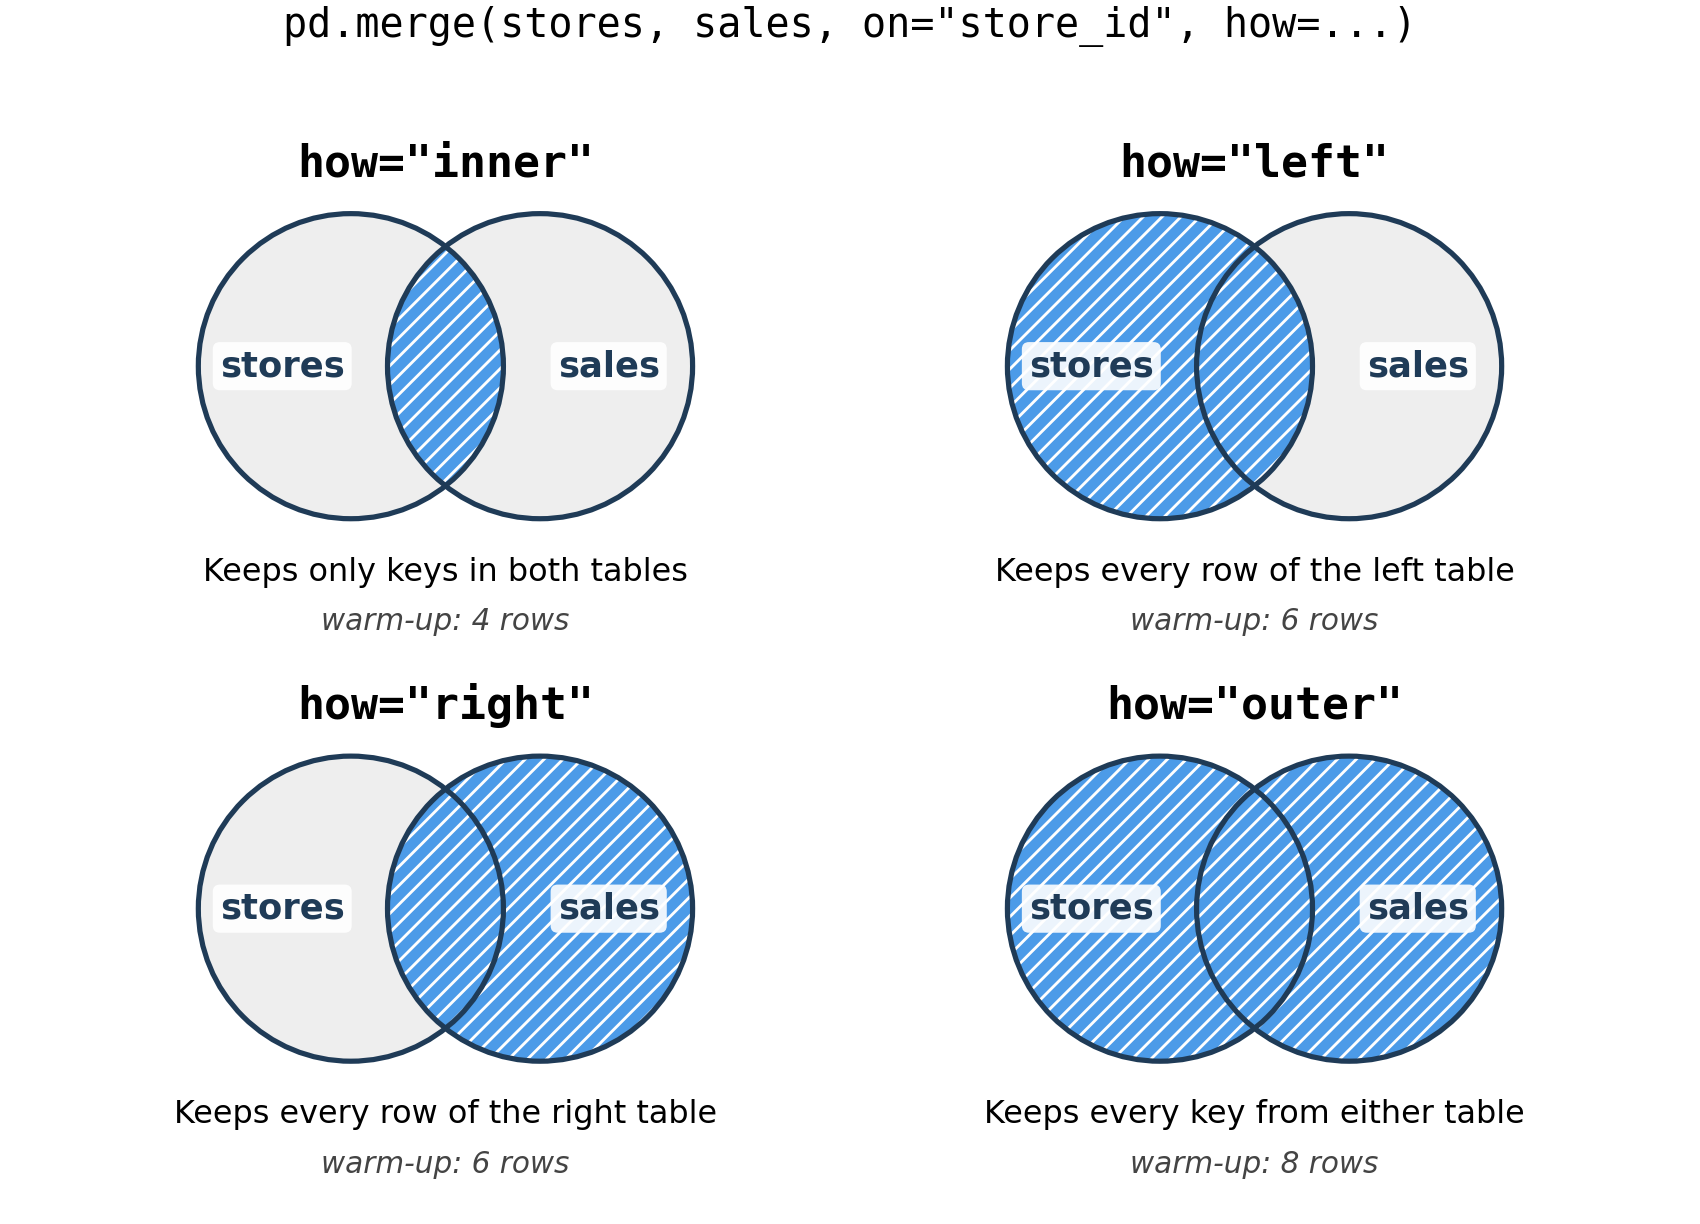

In [ ]:
pd.merge(stores, sales, on="store_id", how="inner")


4 rows: S03 to S06. The other four stores vanished without any message.

`how="left"` keeps **every row of the left table**; where a left key has no match, the right table's columns get `NaN`, Pandas's marker for a missing value.


In [ ]:
pd.merge(stores, sales, on="store_id", how="left")


6 rows, one per store in `stores`. S01 and S02 show `NaN` for `oct_sales`: **no match was found**, which is not the same as \$0 of sales.

`how="right"` is the mirror image: it keeps **every row of the right table**.


In [ ]:
pd.merge(stores, sales, on="store_id", how="right")


6 rows, one per row of `sales`. S07 and S08 show `NaN` for `city`.

`how="outer"` keeps **every key from either table**, with `NaN` wherever a key is missing from one side.


In [ ]:
pd.merge(stores, sales, on="store_id", how="outer")


8 rows: the 4 matches, S01 and S02 with `NaN` sales, and S07 and S08 with `NaN` for `city`. So inner 4, left 6, right 6, outer 8.

Here the key column was ready-made. In real data it often does not exist yet: sometimes merging is harder because you first have to **create the column you merge on**. That is the problem with Starbucks.


## Discussion: how could we combine these?

We want revenue and visits side by side, to see whether revenue per visit changed. But the two tables do not line up:

- `fundq` has one row per **fiscal quarter**, for the whole company.
- `sbux` has one row per **store per week**.

Talk it through with the people at your table:

1. What would need to be true of two tables before you could line their rows up?
2. Which column, or columns, could both tables share?
3. What would you have to do to `sbux` first?

Try your ideas in the empty cells below. Add more cells if you need them.


## Starbucks: bring visits to the quarter

A join works best when both tables have the **same grain** and share **key** columns that name one row. `fundq` names each quarter by `fyearq` and `fqtr`; `sbux` has neither. So:

1. Total the visits over all stores in each week.
2. Give each week a `fyearq` and `fqtr`, built the way Compustat counts Starbucks's fiscal quarters.
3. Total the weeks in each fiscal quarter, and join on `fyearq` and `fqtr`.

Step 1, as in Notebook 9:


In [ ]:
weekly = sbux[["DATE_RANGE_START_dt", "VISIT_COUNTS"]].groupby("DATE_RANGE_START_dt").sum().reset_index()
weekly


509 weeks, from January 2, 2017 to September 28, 2026.

Step 2. As the note under the Compustat preview says, Starbucks's fiscal year ends in September (`fyr` is 9), so fiscal Q1 is October–December and belongs to the **next** calendar year's fiscal year: October 2018 is in fiscal 2019. Each week gets the fiscal quarter of the month its Monday falls in. The snippet below shows the pattern for Q1: start `fqtr` at 0 for every week, then use `.loc` with a mask for October–December, as in Notebook 9. We'll write the other three quarters together.

A week that straddles two quarters goes by the month it starts in. Any reasonable rule works, as long as you apply it the same way to every week.


```python
weekly["month"] = weekly["DATE_RANGE_START_dt"].dt.month
weekly["year"] = weekly["DATE_RANGE_START_dt"].dt.year

weekly["fqtr"] = 0
weekly.loc[(weekly["month"] >= 10) & (weekly["month"] <= 12), "fqtr"] = 1
```


In [ ]:
# Create fqtr here: finish quarters 2 to 4


But our year is still off for Q1, so:



```python
weekly["fyearq"] = weekly["year"]
weekly.loc[weekly["fqtr"] == 1, "fyearq"] += 1
```


In [ ]:
# Create fyearq here


Step 3. Total the weeks in each fiscal quarter. Grouping by **two** columns makes one row for each pair of values, here one row per fiscal year and quarter:


In [ ]:
traffic_q = weekly.groupby(["fyearq", "fqtr"])["VISIT_COUNTS"].sum().reset_index()
traffic_q


In [ ]:
fundq


39 quarters, from fiscal 2017 Q2 to fiscal 2026 Q4. `fundq` also has 39, from fiscal 2017 Q1 to fiscal 2026 Q3: the two tables overlap but do not line up.

## The join: two keys

No single column names a quarter: fiscal year 2019 has four quarters, and `fqtr` 1 comes every year. Together, `fyearq` and `fqtr` name one quarter. When it takes more than one column to make the key, `on=` takes a **list**, and a row matches only when **every** key matches:

```python
pd.merge(traffic_q, fundq, on=["fyearq", "fqtr"], how="inner")
```

The `how=` choices are the same as in the warm-up.

**Predict:** How many quarters are in both tables?


In [ ]:
q_inner = pd.merge(traffic_q, fundq, on=["fyearq", "fqtr"], how="inner")
print("Rows:", len(q_inner))
q_inner.head()


38: fiscal 2017 Q2 through fiscal 2026 Q3. The inner join dropped two quarters without any message: one with visits but no financials, and one with financials but no visits.

## The left join and NaN

**Predict:** How many rows will `q_left` have? Which quarter will show `NaN` for `revtq`?


In [ ]:
q_left = pd.merge(traffic_q, fundq, on=["fyearq", "fqtr"], how="left")
print("Rows:", len(q_left))
q_left.loc[q_left["revtq"].isna()]


39 rows, one for each traffic quarter. Fiscal 2026 Q4 (July–September 2026) has `NaN` for every Compustat column: Starbucks has not reported it yet. As in the warm-up, `NaN` means **no match was found**, not zero revenue. `.sum()` and `.mean()` skip `NaN`, so that quarter is left out rather than counted as \$0.

## The outer join

**Predict:** How many rows? Which quarter will have `NaN` for `VISIT_COUNTS`?


In [ ]:
q_outer = pd.merge(traffic_q, fundq, on=["fyearq", "fqtr"], how="outer")
print("Rows:", len(q_outer))
q_outer.loc[q_outer["VISIT_COUNTS"].isna() | q_outer["revtq"].isna()]


40 rows: the 38 matched quarters, fiscal 2026 Q4 with no financials, and fiscal 2017 Q1 (ending December 31, 2016), which is in Compustat but ends before the traffic data begins.

## Counting rows before you join

When each key appears **once** in each table, three counts predict every join: rows in the left table, rows in the right table, and keys found in both.

| `how=` | Keeps | Rows | Warm-up | Starbucks |
|---|---|---|---|---|
| `"inner"` | keys found in both tables | keys found in both | 4 | 38 |
| `"left"` | every row of the left table | rows in the left table | 6 | 39 |
| `"right"` | every row of the right table | rows in the right table | 6 | 39 |
| `"outer"` | every key from either table | left + right − keys in both | 6 + 6 − 4 = 8 | 39 + 39 − 38 = 40 |

`"right"` is the mirror image of `"left"`: swapping the two tables and using `"left"` keeps the same rows, so most people do that instead.

If a key appears more than once in a table, these counts no longer hold; the optional section shows what happens.


## Exercise 1 — Revenue per visit

> **Your turn:** Work on your own or with your table before we work through this together.

1. Make `sbux_q`: `traffic_q` (left) joined with `fundq` (right) on `fyearq` and `fqtr`, keeping every traffic quarter.
2. Add a column `rev_per_visit` to `sbux_q`: revenue in dollars divided by `VISIT_COUNTS`. `revtq` is in millions, so multiply it by `1_000_000` first. (Python ignores the underscores; they make the number easier to read.)
3. Make `rpv_2019` and `rpv_2025`: the mean `rev_per_visit` over the quarters with `fyearq` equal to 2019 and to 2025. Write each in one line with `.loc` and `.mean()`, as in Notebook 9.

**Predict:** Higher in fiscal 2025, or lower? What will `rev_per_visit` be for the quarters with no financials?


In [ ]:
#@title Check your work { display-mode: "form" }
import math

import numpy as np
import pandas as pd

check_tally = {"passed": 0, "total": 0}


class _NotReady(Exception):
    pass


def need(name, kind=None):
    """Return the student's variable, or stop this one check with a friendly reason."""
    if name not in globals():
        raise _NotReady(name + " does not exist yet. Run your work cell first. If it stopped with an "
                        "error, read the last line of the error, fix it, and rerun the work cell.")
    value = globals()[name]
    if value is None:
        raise _NotReady(name + " is still None. Replace the starter None in your work cell.")
    if kind == "DataFrame" and not isinstance(value, pd.DataFrame):
        if isinstance(value, pd.Series):
            raise _NotReady(name + " is a Series (one column), but this exercise needs a DataFrame. "
                            'Put the column names in a list, as in .loc[rows, ["a", "b"]].')
        raise _NotReady(name + " is a " + type(value).__name__ + ", but this exercise needs a DataFrame.")
    return value


def _short(value):
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, float) and not math.isnan(value):
        value = round(value, 4)
    text = repr(value)
    return text if len(text) <= 160 else text[:160] + "..."


def _matches(actual, expected):
    if isinstance(expected, np.generic):
        expected = expected.item()
    if isinstance(expected, bool):
        return type(actual).__name__ in ("bool", "bool_") and bool(actual) == expected
    if isinstance(expected, float):
        if type(actual).__name__ in ("bool", "bool_", "str"):
            return False
        number = float(actual)
        if math.isnan(expected):
            return math.isnan(number)
        return not math.isnan(number) and abs(number - expected) <= 0.005
    if isinstance(expected, list):
        if not isinstance(actual, list) or len(actual) != len(expected):
            return False
        return all(_matches(a, e) for a, e in zip(actual, expected))
    if isinstance(expected, int):
        if type(actual).__name__ in ("bool", "bool_", "str"):
            return False
        return bool(actual == expected)
    return bool(actual == expected)


def first_difference(labels, actual, expected):
    """Return "all match", or describe the first label whose value differs."""
    actual, expected = list(actual), list(expected)
    if len(actual) != len(expected):
        return str(len(actual)) + " rows, but expected " + str(len(expected))
    for label, got, want in zip(labels, actual, expected):
        if not _matches(got, want):
            return str(label) + ": got " + _short(got) + ", expected " + _short(want)
    return "all match"


def check(case_name, get_actual, expected, hint=""):
    """Run get_actual() safely and report whether it matches expected (a value or a function)."""
    check_tally["total"] = check_tally["total"] + 1
    try:
        if callable(expected):
            expected = expected()
        actual = get_actual()
    except _NotReady as reason:
        print("NOT YET —", case_name + ":", reason)
        return
    except Exception as error:
        print("NOT YET —", case_name + ": checking raised " + type(error).__name__ + ": " + str(error)[:150])
        fallback = "Read the error, fix your work cell, and rerun it before this check."
        print("    Hint:", fallback if callable(hint) or not hint else hint)
        return
    try:
        matched = _matches(actual, expected)
    except Exception:
        matched = False
    if matched:
        check_tally["passed"] = check_tally["passed"] + 1
        print("✓", case_name, "— passed")
    else:
        print("NOT YET —", case_name + ": expected", _short(expected), "but got", _short(actual))
        if callable(hint):
            hint = hint(actual)
        if hint:
            print("    Hint:", hint)


def check_summary(label):
    """Print how many checks passed."""
    if check_tally["passed"] == check_tally["total"]:
        print(label + ": all " + str(check_tally["total"]) + " checks passed ✓")
    else:
        print(label + ": NOT YET — " + str(check_tally["passed"]) + " of " + str(check_tally["total"])
              + " checks passed. Fix the first NOT YET line, rerun your work cell, then rerun this check.")


def need_sbux():
    """Return sbux, or stop this one check if it is not loaded."""
    table = globals().get("sbux")
    if not isinstance(table, pd.DataFrame) or len(table) == 0:
        raise _NotReady("sbux is not loaded. Paste the class code from Canvas into CLASS_KEY, rerun the "
                        "download cell, then rerun your work cell.")
    return table


KEYS = ["fyearq", "fqtr"]


def _expected():
    need_sbux()
    table = pd.merge(need("traffic_q", "DataFrame"), need("fundq", "DataFrame"), on=KEYS, how="left")
    table["rpv"] = table["revtq"] * 1_000_000 / table["VISIT_COUNTS"]
    return table


def _table():
    table = need("sbux_q", "DataFrame")
    for column in (*KEYS, "VISIT_COUNTS", "revtq", "rev_per_visit"):
        if column not in table.columns:
            raise _NotReady("sbux_q has no " + column + " column yet.")
    return table.sort_values(KEYS)


def _labels():
    table = _expected().sort_values(KEYS)
    return ("FY" + table["fyearq"].astype(str) + " Q" + table["fqtr"].astype(str)).tolist()


def _rows_hint(actual):
    if actual == len(pd.merge(need("traffic_q", "DataFrame"), need("fundq", "DataFrame"), on=KEYS, how="inner")):
        return 'That is the inner join\'s row count. Use how="left" to keep every traffic quarter.'
    return 'Use pd.merge(traffic_q, fundq, on=["fyearq", "fqtr"], how="left").'


def _year(value):
    table = _expected()
    return float(table.loc[table["fyearq"] == value, "rpv"].mean())


check("sbux_q rows", lambda: len(_table()), lambda: len(_expected()), _rows_hint)
check("rev_per_visit (each quarter)",
      lambda: first_difference(_labels(), _table()["rev_per_visit"].tolist(),
                               _expected().sort_values(KEYS)["rpv"].tolist()),
      "all match", 'Use sbux_q["revtq"] * 1_000_000 / sbux_q["VISIT_COUNTS"].')
check("rpv_2019", lambda: float(need("rpv_2019")), lambda: _year(2019),
      'Use sbux_q.loc[sbux_q["fyearq"] == 2019, "rev_per_visit"].mean().')
check("rpv_2025", lambda: float(need("rpv_2025")), lambda: _year(2025), "Use the same line with 2025.")
check_summary("Exercise 1")


Revenue per visit rose from about \$9.06 in fiscal 2019 to about \$12.90 in fiscal 2025. The quarter without financials has `NaN` for `rev_per_visit`: dividing `NaN` by a number gives `NaN`, and `.mean()` skips them.

Revenue per visit is not the price of a coffee. Revenue covers every country and channel, including licensed stores and packaged coffee, while visits are estimates for US stores. Use the ratio to compare quarters with each other. An auditor who expected revenue to follow visits would ask what explains a 42% rise: higher prices, larger orders, or more drive-thru and mobile orders that a foot-traffic count may miss. A gap is a question to answer, not an error by itself.


## The same join, written another way

You will also see joins written as a method on the left table, for example in the Pandas documentation: `left.merge(right, on=..., how=...)`. It is exactly the same join; the table before `.merge` is the left table. The cell below checks that both forms give the same table.


In [ ]:
pd.merge(traffic_q, fundq, on=["fyearq", "fqtr"], how="left").equals(traffic_q.merge(fundq, on=["fyearq", "fqtr"], how="left"))


## Retrieval

Answer on paper, without running code:

1. In `q_left`, why does fiscal 2026 Q4 show `NaN` for `revtq`, and why would replacing it with 0 be wrong?
2. How many rows would `pd.merge(fundq, traffic_q, on=["fyearq", "fqtr"], how="left")` have? Which column would hold `NaN`, and in which quarter?
3. What would go wrong if you joined on `fqtr` alone, `on="fqtr"`? About how many rows would the inner join return?

## Recap

- When both tables already share a key, the join is one line: `pd.merge(stores, sales, on="store_id", how=...)`.
- Bring detail rows to the grain of the financial table first: here, weeks to quarters.
- Build the key the same way as the other table: here, `fyearq` and `fqtr` from the month each week starts in.
- `pd.merge(left, right, on="key", how=...)` matches rows only where the key is exactly equal. When one column cannot name a row, `on=` takes a list, such as `on=["fyearq", "fqtr"]`, and a row matches only when every key matches. The first table is the left table. `left.merge(right, ...)` is the same join.
- `how="inner"` (the default) keeps keys found in both tables; `"left"` keeps every left row; `"outer"` keeps every key from either table.
- When each key appears once per table: inner = keys in both, left = left rows, outer = left rows + right rows − keys in both.
- A row with no match gets `NaN` in the other table's columns. `NaN` means "no match," not zero. Find those rows with a `.isna()` mask.
- An inner join drops unmatched rows without saying so. Count rows before and after every join.

Before finishing, use **Runtime → Restart session and run all**. Your Exercise 1 check should pass.


## Optional: a repeated key multiplies rows

So far each key appeared once in each table. Suppose we skip the quarterly totals and join `fundq` straight onto `weekly`, where each `fyearq`–`fqtr` pair appears once for every week of the quarter.

**Predict:** How many rows? And what happens if we then add up `revtq`?


In [ ]:
repeated = pd.merge(weekly, fundq, on=["fyearq", "fqtr"], how="left")
print("Rows:", len(repeated))
print("revtq added up after the join ($ millions):", round(repeated["revtq"].sum()))
print("revtq added up in fundq ($ millions):", round(fundq["revtq"].sum()))


509 rows, one per week, and each quarter's revenue is copied onto each of its 13 or so weeks. Adding up `revtq` counts every quarter about 13 times: about \$3.8 trillion instead of \$297 billion. The join ran without an error; the mistake was **adding up a total that the join had repeated**. The fix is order: total the weeks to one row per quarter first, as `traffic_q` does.

`validate=` makes Pandas check the keys before it joins. `validate="one_to_one"` says each key should appear at most once in **each** table; `validate="many_to_one"` allows repeats on the left but not on the right. If the check fails, the merge stops with a `MergeError` instead of quietly repeating rows. Remove the `#` at the start of the line below and run it to see the error, then put the `#` back so **Run all** keeps working.


In [ ]:
# pd.merge(weekly, fundq, on=["fyearq", "fqtr"], how="left", validate="one_to_one")


The error says the merge keys are not unique in the left dataset: `weekly` has 13 or so rows for each fiscal quarter. With `traffic_q` on the left, `validate="one_to_one"` passes.
